In [1]:
src\products\views.py

SyntaxError: unexpected character after line continuation character (1762771327.py, line 1)

In [ ]:
from django.shortcuts import render, get_object_or_404
from django.http import HttpResponseRedirect
#from django.views.generic import View, ListView, TemplateView
from django.views.generic import ListView, DetailView, RedirectView, CreateView, UpdateView, DeleteView
from django.views.decorators.http import require_http_methods
from django.contrib.auth.mixins import LoginRequiredMixin
from .forms import ProductModelForm
from .models import Product, DigitalProduct
from .mixins import TemplateTitleMixin

class ProtectedListView(TemplateTitleMixin, LoginRequiredMixin, ListView):
    model = Product
    template_name = "products/product_list.html"
    title = "Productos Fisicos creados por ti"
    def get_queryset(self):
        return Product.objects.filter(user=self.request.user)


In [ ]:
src\products\urls.py

In [ ]:
from django.contrib import admin
from django.urls import path
from django.views.generic import TemplateView, RedirectView
from products.views import (
    ProductListView, 
    ProductDetailView, 
    DigitalProductListView, 
    ProductIDRedirectView, 
    ProductRedirectView, 
    ProtectedProductDetailView,
    ProtectedProductCreateView,
    ProtectedProductUpdateView,
    ProtectedProductDeleteView,
    ProtectedListView,
    )

urlpatterns = [
    path("admin/", admin.site.urls),
    path("team/", TemplateView.as_view(template_name="team.html")),
    path("products/", ProductListView.as_view()),
    path("digital-products/", DigitalProductListView.as_view()),
    path("products/<int:pk>/", ProductDetailView.as_view()),
    path("products/<slug:slug>/", ProductDetailView.as_view()),
    path("my-products/create/", ProtectedProductCreateView.as_view()),
    path("p/<int:pk>/", ProductIDRedirectView.as_view()),
    path("p/<slug:slug>/", ProductRedirectView.as_view()),
    path("my-products/<slug:slug>/", ProtectedProductUpdateView.as_view()),
    path("my-products/<slug:slug>/delete/", ProtectedProductDeleteView.as_view()),
    path("my-products/", ProtectedListView.as_view()) #<----------------
    # path("my-products/<slug:slug>/", ProtectedProductDetailView.as_view()),
]

## Captura de my-products con sesion iniciada 
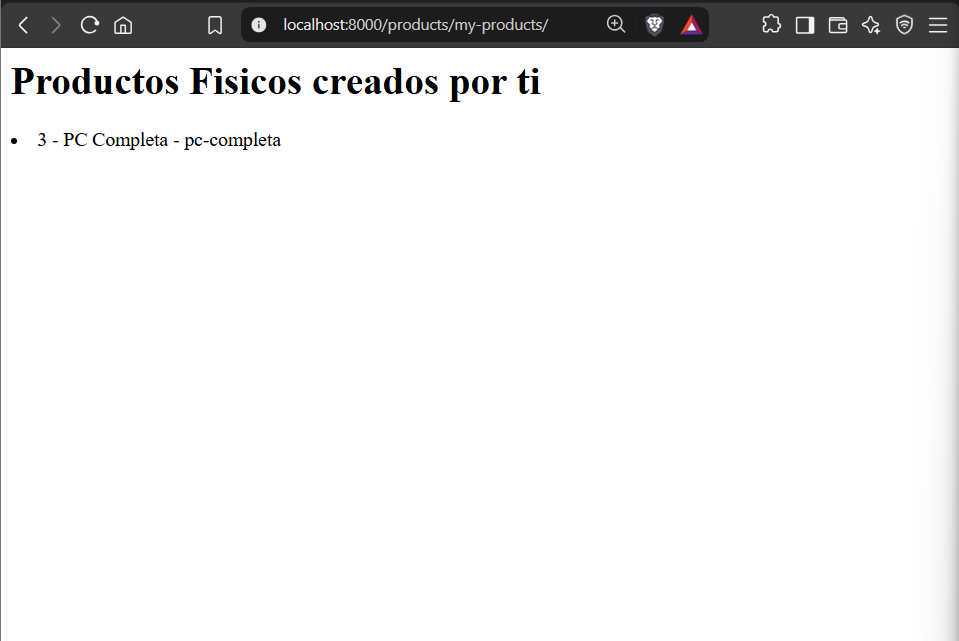

## Captura de my-products sin sesion
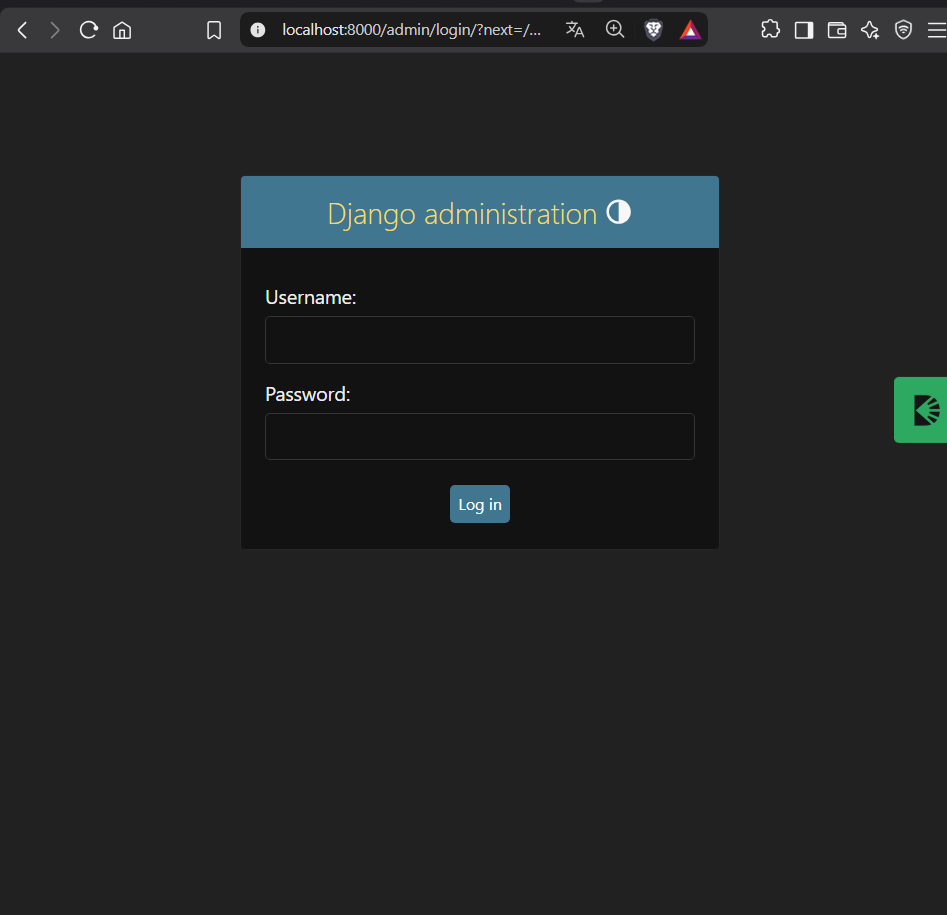